# Download OOD Test Sample from OpenFake `core/test`

This notebook pulls a small **out-of-distribution (OOD) test set** from the
[OpenFake](https://huggingface.co/datasets/ComplexDataLab/OpenFake) dataset
and saves it to Google Drive, ready for evaluation on Kaggle.

### What makes this OOD?

The `core/test` split isolates **two axes of distribution shift simultaneously**:

1. **Unseen generators** — models your detector has never trained on.
2. **Unseen real-image distribution** — real photographs that were not in the training pool.

This is a stricter generalisation test than holding out generators alone, because
the detector cannot rely on superficial cues from the real-image distribution either.

### How OOD generators are identified

Rather than maintaining a manual list, this notebook **scans the first 10K samples**
of the `core/test` split and automatically labels any generator that was NOT in the
training set as OOD.  The training set contained only:

- Real images
- Midjourney variants (`midjourney-6`, `midjourney-7`)
- Stable Diffusion variants (`sd-1.5`, `sd-2.1`, `sd-3.5`, `sdxl`, and their finetunes)

Everything else is OOD.

### Output structure

```
openfake_ood_test_256/
├── ood_test/
│   ├── real/        # unseen real images
│   └── fake/        # images from OOD generators
├── metadata/
│   └── ood_test_metadata.csv   # image_path, prompt, label, model
└── eda/
    ├── ood_summary.txt
    ├── ood_model_counts.csv
    ├── ood_generator_distribution.png
    └── ood_sample_grid.png
```

The output is compatible with the `DeepfakeDataset` class from the CLIP-LoRA
training notebook — just point `image_root` at the output directory and use
`split="ood_test"`.

## 1. Setup

In [1]:
!pip -q install datasets pillow tqdm pandas matplotlib

In [2]:
import os
import io
import csv
import shutil
import random
import zipfile
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage, ImageOps
from tqdm.auto import tqdm
from datasets import load_dataset, Image

try:
    from google.colab import drive
    IN_COLAB = True
except Exception:
    IN_COLAB = False

print("IN_COLAB:", IN_COLAB)

IN_COLAB: True


## 2. Configuration

All tuneable parameters live here.  OOD generators are discovered automatically
in the scan step — the only thing defined here is what counts as **in-distribution**
(i.e. the generators that were in your training set).

In [3]:
# ============================================================
# SAMPLING
# ============================================================
IMAGES_PER_MODEL = 50       # fake images to collect per OOD generator
REAL_IMAGES_TOTAL = None    # auto-set after scan to match total fakes
MIN_MODEL_COUNT = 25        # skip generators with fewer than this in the scan

SEED = 42

# ============================================================
# IMAGE PREPROCESSING  (must match your training pipeline)
# ============================================================
TARGET_SIZE = (256, 256)
JPEG_QUALITY = 95

# ============================================================
# TRAINING SET MODELS — these are IN-distribution, skip them
# ============================================================
# Your training subset (from OpenFake_EDA.ipynb) filtered for:
#   - real images
#   - anything with "midjourney" in the model name
#   - anything with "sd", "stable", or "sdxl" in the model name
#
# So any generator NOT matching these substrings is OOD.
# ============================================================
TRAIN_MODEL_SUBSTRINGS = [
    "midjourney",
    "sd-",
    "sdxl",
    "stable",
]


def is_train_generator(model_name: str) -> bool:
    """Return True if this generator was in the training set."""
    mn = model_name.lower()
    return any(sub in mn for sub in TRAIN_MODEL_SUBSTRINGS)


# ============================================================
# PATHS
# ============================================================
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Image Processing Project")
DRIVE_OUTPUT_DIR  = DRIVE_PROJECT_DIR / "OOD Dataset"

# Local working directory (faster I/O than Drive)
LOCAL_BASE = Path("/content/openfake_ood_test_256")
LOCAL_IMG  = LOCAL_BASE / "ood_test"
LOCAL_META = LOCAL_BASE / "metadata"
LOCAL_EDA  = LOCAL_BASE / "eda"

print(f"Images per generator:     {IMAGES_PER_MODEL}")
print(f"Min model count to keep:  {MIN_MODEL_COUNT}")
print(f"Drive output:             {DRIVE_OUTPUT_DIR}")

Images per generator:     50
Min model count to keep:  25
Drive output:             /content/drive/MyDrive/Image Processing Project/OOD Dataset


## 3. Mount Google Drive

In [4]:
if IN_COLAB:
    drive.mount("/content/drive")
    assert DRIVE_PROJECT_DIR.exists(), (
        f"Project directory not found: {DRIVE_PROJECT_DIR}\n"
        f"Make sure the shared folder is added as a shortcut to My Drive."
    )
    # Create OOD folder if it doesn't exist
    DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Drive mounted.  Output dir: {DRIVE_OUTPUT_DIR}")
else:
    print("Not in Colab — skipping Drive mount.")

Mounted at /content/drive
Drive mounted.  Output dir: /content/drive/MyDrive/Image Processing Project/OOD Dataset


## 4. Stream the `core/test` split

We stream directly from HuggingFace so we never need to download the entire
multi-GB dataset.  The critical trick (learned the hard way in `OpenFake_EDA.ipynb`)
is to **disable automatic image decoding** with `cast_column("image", Image(decode=False))`.
Without this, the HF datasets library tries to decode every image eagerly and
crashes on malformed entries.

OpenFake has two configs (`core` and `reddit`), so we pass `"core"` as the config
name and `"test"` as the split.

In [5]:
dataset = load_dataset(
    "ComplexDataLab/OpenFake",
    "core",
    split="test",
    streaming=True,
)
print("Loaded config='core', split='test'")

# CRITICAL: disable auto-decode to prevent crashes on broken images
dataset = dataset.cast_column("image", Image(decode=False))

# Quick sanity check
sample = next(iter(dataset))
print(f"\nSample keys: {list(sample.keys())}")
print(f"Label: {sample.get('label', 'N/A')}")
print(f"Model: {sample.get('model', 'N/A')}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Loaded config='core', split='test'

Sample keys: ['image', 'prompt', 'label', 'model', 'type', 'release_date']
Label: fake
Model: z-image-turbo


## 5. Scan available models & auto-discover OOD generators

We scan the first 10K samples to catalogue every generator name in the split,
then automatically flag anything that wasn't in the training set as OOD.
Generators with very few samples (below `MIN_MODEL_COUNT`) are skipped.

In [6]:
# Re-initialise the stream (HF streaming iterators are single-pass)
scan_ds = load_dataset(
    "ComplexDataLab/OpenFake",
    "core",
    split="test",
    streaming=True,
)
scan_ds = scan_ds.cast_column("image", Image(decode=False))

# Scan first N samples
SCAN_LIMIT = 10_000
scan_models = Counter()
scan_labels = Counter()
# Track which model names appear with label="real"
real_model_names = set()

for i, ex in enumerate(scan_ds):
    if i >= SCAN_LIMIT:
        break
    model = ex.get("model", "unknown")
    label = ex.get("label", "unknown")
    scan_models[model] += 1
    scan_labels[label] += 1
    if label.lower() == "real":
        real_model_names.add(model)

print(f"Scanned {min(i+1, SCAN_LIMIT)} samples")
print(f"\n{'=' * 60}")
print("LABELS")
print("=" * 60)
for label, cnt in scan_labels.most_common():
    print(f"  {label:>20s}: {cnt:>6d}")

# Auto-discover OOD generators
print(f"\n{'=' * 60}")
print("GENERATOR CLASSIFICATION")
print("=" * 60)

OOD_GENERATORS = {}

for model, count in scan_models.most_common():
    # Skip real-image sources (models that appear with label="real")
    if model in real_model_names:
        print(f"  SKIP (real source):     {model:>40s}: {count:>5d}")
        continue

    # Skip in-distribution generators
    if is_train_generator(model):
        print(f"  SKIP (in training set): {model:>40s}: {count:>5d}")
        continue

    # Skip generators with too few samples
    if count < MIN_MODEL_COUNT:
        print(f"  SKIP (too few, {count}<{MIN_MODEL_COUNT}):  {model:>40s}: {count:>5d}")
        continue

    OOD_GENERATORS[model] = count
    print(f"  OOD:                   {model:>40s}: {count:>5d}")

# Auto-set real target HIGHER than fakes to guarantee enough
total_ood_fakes = sum(min(c, IMAGES_PER_MODEL) for c in OOD_GENERATORS.values())
REAL_IMAGES_TOTAL = int(total_ood_fakes * 1.5)  # overshoot to be safe

print(f"\n{'=' * 60}")
print(f"OOD generators to download: {len(OOD_GENERATORS)}")
print(f"Fake images target:         {total_ood_fakes}")
print(f"Real images target:         {REAL_IMAGES_TOTAL}")

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Scanned 10000 samples

LABELS
                  real:   5073
                  fake:   4927

GENERATOR CLASSIFICATION
  SKIP (real source):                                     imagenet:  3404
  SKIP (real source):                                        docci:  1669
  OOD:                                              z-image-turbo:  1405
  OOD:                                            flux.2-klein-9b:   903
  OOD:                                                illustrious:   681
  OOD:                                              gpt-image-1.5:   604
  SKIP (in training set):                             midjourney-7:   381
  OOD:                                                      veo-3:   216
  OOD:                                              wan-video-2.5:   134
  OOD:                                                 recraft-v3:   104
  OOD:                                          ernie-image-turbo:    78
  OOD:                                                     sora-2:    60
  O

## 6. Download & preprocess OOD images

For each streamed sample we check:

1. If `label == "real"` and we still need real images → save it.
2. If the model name is in our discovered OOD set and under the cap → save it.
3. Otherwise → skip.

Every saved image is resized to **256×256** using `ImageOps.fit` (centre-crop
then resize, same as the preprocessing notebook) and written as JPEG at
quality 95.

In [7]:
# Create local output directories
for d in [LOCAL_IMG / "real", LOCAL_IMG / "fake", LOCAL_META, LOCAL_EDA]:
    d.mkdir(parents=True, exist_ok=True)

print("Output directories created:")
print(f"  Images (real): {LOCAL_IMG / 'real'}")
print(f"  Images (fake): {LOCAL_IMG / 'fake'}")
print(f"  Metadata:      {LOCAL_META}")
print(f"  EDA:           {LOCAL_EDA}")

Output directories created:
  Images (real): /content/openfake_ood_test_256/ood_test/real
  Images (fake): /content/openfake_ood_test_256/ood_test/fake
  Metadata:      /content/openfake_ood_test_256/metadata
  EDA:           /content/openfake_ood_test_256/eda


In [8]:
# Re-initialise the stream for the actual download
dl_dataset = load_dataset(
    "ComplexDataLab/OpenFake",
    "core",
    split="test",
    streaming=True,
)
dl_dataset = dl_dataset.cast_column("image", Image(decode=False))

# Counters
fake_counts = Counter()
real_count = 0
skip_count = 0
img_id = 0

real_target = REAL_IMAGES_TOTAL

# CSV writer
csv_path = LOCAL_META / "ood_test_metadata.csv"
csv_file = open(csv_path, "w", newline="", encoding="utf-8")
writer = csv.writer(csv_file)
writer.writerow(["image_path", "prompt", "label", "model"])

pbar = tqdm(desc="Downloading OOD test images", unit="img")

iterator = iter(dl_dataset)

while True:
    try:
        example = next(iterator)
    except StopIteration:
        print("\nReached end of dataset stream.")
        break
    except Exception:
        skip_count += 1
        continue

    model_name = example.get("model", "").strip()
    label_name = example.get("label", "").strip().lower()
    prompt = example.get("prompt", "")

    # Decide whether to keep
    save_as = None

    if label_name == "real" and real_count < real_target:
        save_as = "real"
    elif label_name != "real" and model_name in OOD_GENERATORS:
        if fake_counts[model_name] < IMAGES_PER_MODEL:
            save_as = "fake"

    if save_as is None:
        continue

    # Decode, resize, save
    try:
        img_bytes = example["image"]["bytes"]
        img = PILImage.open(io.BytesIO(img_bytes))

        if img.mode != "RGB":
            img = img.convert("RGB")

        # Centre-crop + resize to target (matches Colab_Preprocess pipeline)
        img = ImageOps.fit(img, TARGET_SIZE, method=PILImage.LANCZOS)

        fname = f"{img_id}.jpg"
        out_path = LOCAL_IMG / save_as / fname
        img.save(str(out_path), "JPEG", quality=JPEG_QUALITY)

        writer.writerow([
            str(out_path),
            prompt,
            save_as,
            model_name if save_as == "fake" else "real",
        ])

        if save_as == "real":
            real_count += 1
        else:
            fake_counts[model_name] += 1

        img_id += 1
        pbar.update(1)

    except Exception:
        skip_count += 1
        continue

    # Stop condition
    all_fakes_done = all(
        fake_counts.get(m, 0) >= IMAGES_PER_MODEL
        for m in OOD_GENERATORS
    )
    real_done = real_count >= real_target

    if all_fakes_done and real_done:
        print("\nAll targets reached.")
        break

csv_file.close()
pbar.close()

total_fake = sum(fake_counts.values())
print(f"\n{'=' * 60}")
print(f"DOWNLOAD COMPLETE")
print(f"{'=' * 60}")
print(f"  Real images:    {real_count}")
print(f"  Fake images:    {total_fake}  ({len(fake_counts)} generators)")
print(f"  Total saved:    {img_id}")
print(f"  Skipped/errors: {skip_count}")
print(f"\nPer-generator breakdown:")
for model, cnt in fake_counts.most_common():
    print(f"  {model:>40s}: {cnt:>4d}")

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/608 [00:00<?, ?it/s]


All targets reached.

DOWNLOAD COMPLETE
  Real images:    1177
  Fake images:    900  (18 generators)
  Total saved:    2077
  Skipped/errors: 0

Per-generator breakdown:
                             z-image-turbo:   50
                             wan-video-2.5:   50
                                    sora-2:   50
                               illustrious:   50
                           flux.2-klein-9b:   50
                              ideogram-2.0:   50
                             seedream-v5.0:   50
                             gpt-image-1.5:   50
                         ernie-image-turbo:   50
                           nano-banana-pro:   50
                                recraft-v3:   50
                                     veo-3:   50
                               ernie-image:   50
                                recraft-v2:   50
                               gpt-image-2:   50
                            frames-23-1-25:   50
                            lumina-17-2-25: 

## 7. Rebalance real images (optional)

If we collected more real images than fakes (or vice versa), randomly trim the
larger class to match.  Balanced classes make metrics like accuracy directly
interpretable without reasoning about class priors.

In [9]:
random.seed(SEED)

real_dir = LOCAL_IMG / "real"
fake_dir = LOCAL_IMG / "fake"

n_real = len(list(real_dir.glob("*.jpg")))
n_fake = len(list(fake_dir.glob("*.jpg")))

print(f"Current counts:  real={n_real}, fake={n_fake}")

if n_real >= n_fake:
    print("Real >= Fake — already balanced or real-heavy, nothing to do.")
else:
    shortfall = n_fake - n_real
    print(f"Need {shortfall} more real images to match fakes.")
    print("Downloading additional real images...")

    # Stream more real images to fill the gap
    extra_ds = load_dataset(
        "ComplexDataLab/OpenFake",
        "core",
        split="test",
        streaming=True,
    )
    extra_ds = extra_ds.cast_column("image", Image(decode=False))

    # Find the current max image ID so we don't overwrite
    existing_ids = [int(f.stem) for f in real_dir.glob("*.jpg")]
    next_id = max(existing_ids) + 1 if existing_ids else 0

    # Also load existing metadata to track what we already have
    existing_real_prompts = set()
    if csv_path.exists():
        tmp_df = pd.read_csv(csv_path)
        existing_real_prompts = set(
            tmp_df[tmp_df["label"] == "real"]["prompt"].dropna().values
        )

    extra_csv = open(csv_path, "a", newline="", encoding="utf-8")
    extra_writer = csv.writer(extra_csv)

    added = 0
    skipped = 0

    for ex in tqdm(extra_ds, desc="Fetching extra reals", unit="img"):
        if added >= shortfall:
            break

        label = ex.get("label", "").strip().lower()
        if label != "real":
            continue

        # Skip duplicates (by prompt, rough dedup)
        prompt = ex.get("prompt", "")
        if prompt in existing_real_prompts:
            continue

        try:
            img_bytes = ex["image"]["bytes"]
            img = PILImage.open(io.BytesIO(img_bytes))
            if img.mode != "RGB":
                img = img.convert("RGB")
            img = ImageOps.fit(img, TARGET_SIZE, method=PILImage.LANCZOS)

            fname = f"{next_id}.jpg"
            out_path = real_dir / fname
            img.save(str(out_path), "JPEG", quality=JPEG_QUALITY)

            extra_writer.writerow([str(out_path), prompt, "real", "real"])

            existing_real_prompts.add(prompt)
            next_id += 1
            added += 1

        except Exception:
            skipped += 1
            continue

    extra_csv.close()
    print(f"Added {added} extra real images (skipped {skipped} errors).")

# Final count
n_real_final = len(list(real_dir.glob("*.jpg")))
n_fake_final = len(list(fake_dir.glob("*.jpg")))
print(f"Final counts:    real={n_real_final}, fake={n_fake_final}")

Current counts:  real=1177, fake=900
Real >= Fake — already balanced or real-heavy, nothing to do.
Final counts:    real=1177, fake=900


## 8. Rebuild metadata after rebalance

The initial CSV was written during streaming.  After trimming, we rebuild it
to reflect only the images that actually survived, and update paths to be
relative (so they work on Kaggle too).

In [10]:
raw_df = pd.read_csv(csv_path)

surviving_real = {f.name for f in (LOCAL_IMG / "real").glob("*.jpg")}
surviving_fake = {f.name for f in (LOCAL_IMG / "fake").glob("*.jpg")}
surviving_all = surviving_real | surviving_fake

# Extract filename from the full path stored in CSV
raw_df["fname"] = raw_df["image_path"].apply(lambda p: Path(p).name)
clean_df = raw_df[raw_df["fname"].isin(surviving_all)].copy()

# Rewrite image_path as relative (works on both Colab and Kaggle)
clean_df["image_path"] = clean_df.apply(
    lambda r: f"ood_test/{r['label']}/{r['fname']}",
    axis=1,
)
clean_df.drop(columns=["fname"], inplace=True)

# Save
clean_csv = LOCAL_META / "ood_test_metadata.csv"
clean_df.to_csv(clean_csv, index=False)

print(f"Metadata saved: {clean_csv}")
print(f"  Rows: {len(clean_df)}")
print(f"  Columns: {list(clean_df.columns)}")
clean_df.head()

Metadata saved: /content/openfake_ood_test_256/metadata/ood_test_metadata.csv
  Rows: 2077
  Columns: ['image_path', 'prompt', 'label', 'model']


,image_path,prompt,label,model
0,ood_test/fake/0.jpg,Tuarichit art style. Cinematic overhead shot: ...,fake,z-image-turbo
1,ood_test/real/1.jpg,NaN,real,real
2,ood_test/real/2.jpg,NaN,real,real
3,ood_test/real/3.jpg,NaN,real,real
4,ood_test/real/4.jpg,NaN,real,real


## 9. Quick EDA

Sanity-check the composition before uploading to Kaggle.

In [11]:
# Class distribution
label_dist = clean_df["label"].value_counts()
print("Class distribution:")
print(label_dist)

# Per-model breakdown
model_dist = (
    clean_df[clean_df["label"] == "fake"]
    .groupby("model")
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
print(f"\nPer-model breakdown ({len(model_dist)} OOD generators):")
print(model_dist.to_string(index=False))

# Save EDA
summary_lines = [
    "OpenFake OOD Test Sample — Summary",
    "=" * 50,
    f"Total images:     {len(clean_df)}",
    f"  Real:           {label_dist.get('real', 0)}",
    f"  Fake:           {label_dist.get('fake', 0)}",
    f"OOD generators:   {clean_df[clean_df['label']=='fake']['model'].nunique()}",
    f"Image size:       {TARGET_SIZE[0]}x{TARGET_SIZE[1]}",
    "",
    "Per-generator counts:",
    model_dist.to_string(index=False),
]
summary_text = "\n".join(summary_lines)
(LOCAL_EDA / "ood_summary.txt").write_text(summary_text)
model_dist.to_csv(LOCAL_EDA / "ood_model_counts.csv", index=False)
print(f"\nEDA saved to {LOCAL_EDA}")

Class distribution:
label
real    1177
fake     900
Name: count, dtype: int64

Per-model breakdown (18 OOD generators):
            model  count
   aurora-20-1-25     50
      ernie-image     50
ernie-image-turbo     50
  flux.2-klein-9b     50
   frames-23-1-25     50
    gpt-image-1.5     50
      gpt-image-2     50
     ideogram-2.0     50
      illustrious     50
   lumina-17-2-25     50
  nano-banana-pro     50
       recraft-v2     50
       recraft-v3     50
    seedream-v5.0     50
           sora-2     50
            veo-3     50
    wan-video-2.5     50
    z-image-turbo     50

EDA saved to /content/openfake_ood_test_256/eda


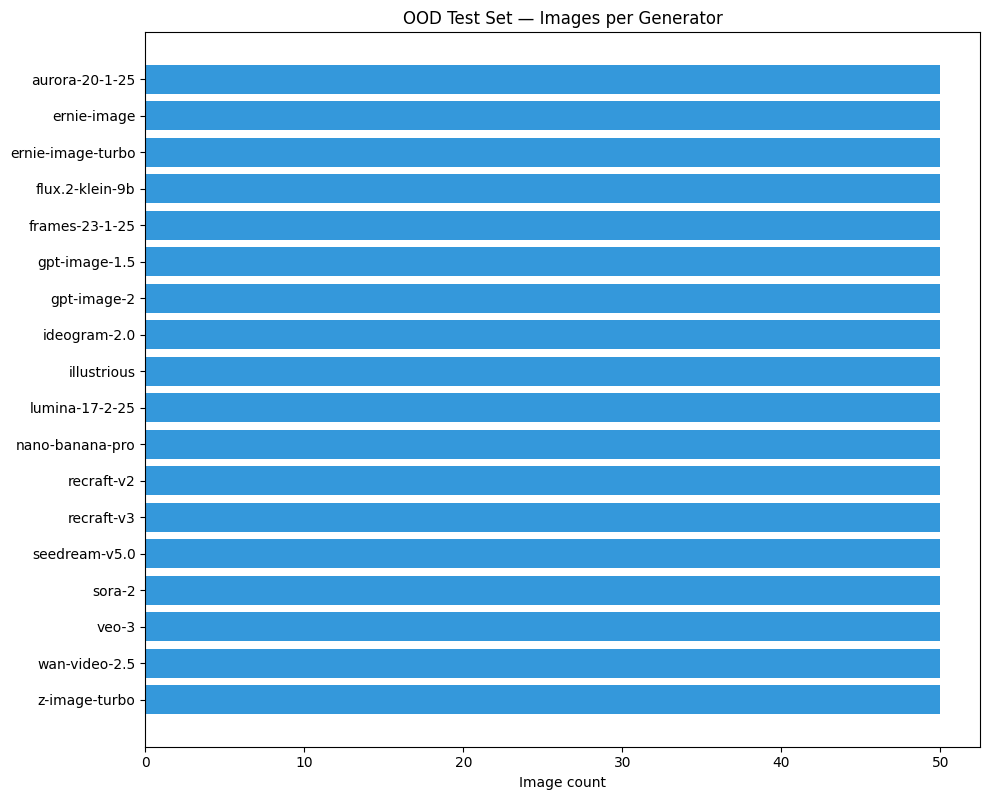

In [12]:
# Bar chart of per-generator counts
fig, ax = plt.subplots(figsize=(10, max(4, len(model_dist) * 0.45)))

ax.barh(model_dist["model"], model_dist["count"], color="#3498db")
ax.set_xlabel("Image count")
ax.set_title("OOD Test Set — Images per Generator")
ax.invert_yaxis()

plt.tight_layout()
fig.savefig(str(LOCAL_EDA / "ood_generator_distribution.png"), dpi=150)
plt.show()

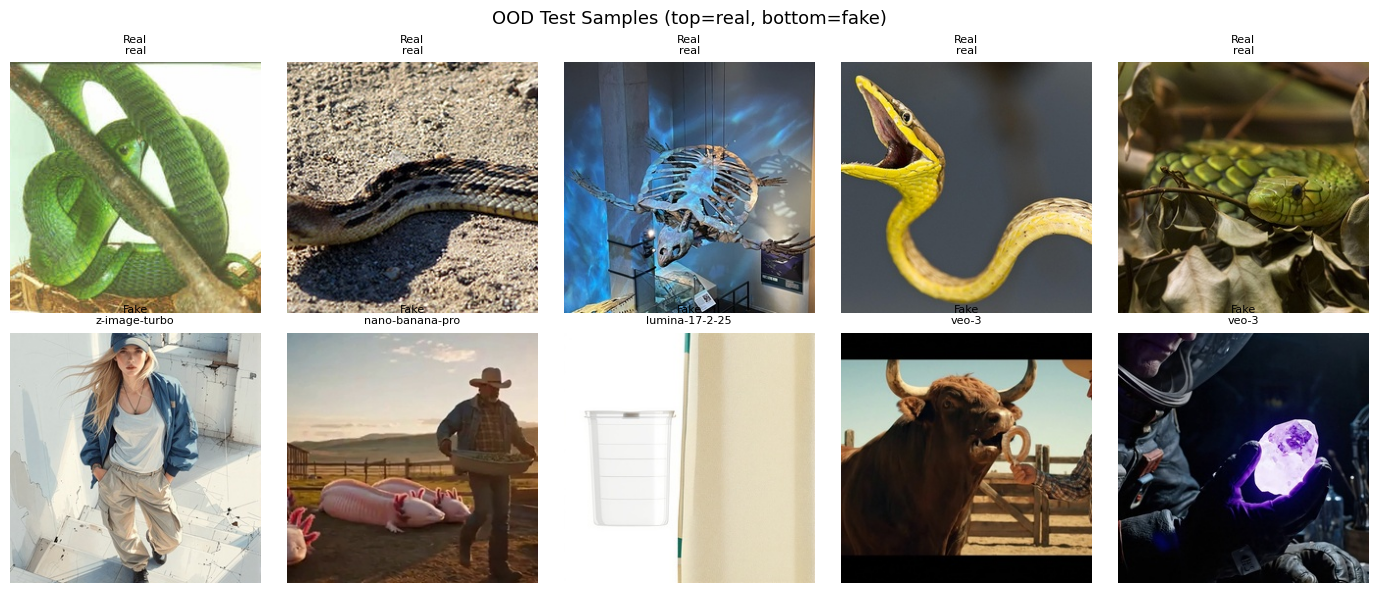

In [13]:
# Visual spot-check: grid of sample images
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle("OOD Test Samples (top=real, bottom=fake)", fontsize=13)

real_samples = sorted((LOCAL_IMG / "real").glob("*.jpg"))[:5]
fake_samples = sorted((LOCAL_IMG / "fake").glob("*.jpg"))[:5]

for i, (row_files, row_label) in enumerate([(real_samples, "Real"), (fake_samples, "Fake")]):
    for j, fpath in enumerate(row_files):
        ax = axes[i][j]
        img = PILImage.open(fpath)
        ax.imshow(img)
        # Look up model name from metadata
        fname = fpath.name
        match = clean_df[clean_df["image_path"].str.endswith(fname)]
        model = match["model"].values[0] if len(match) > 0 else "?"
        ax.set_title(f"{row_label}\n{model}", fontsize=8)
        ax.axis("off")

plt.tight_layout()
fig.savefig(str(LOCAL_EDA / "ood_sample_grid.png"), dpi=150)
plt.show()

## 10. Save to Google Drive

Copy the processed dataset to `Image Processing Project/OOD/` on Drive and
create a ZIP archive for uploading to Kaggle.

In [14]:
# Create ZIP archive
zip_path = "/content/openfake_ood_test_256.zip"

print(f"Creating ZIP archive at {zip_path} ...")
shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    str(LOCAL_BASE),
)

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"ZIP created: {zip_path}  ({zip_size_mb:.1f} MB)")

Creating ZIP archive at /content/openfake_ood_test_256.zip ...
ZIP created: /content/openfake_ood_test_256.zip  (67.8 MB)


In [15]:
if IN_COLAB:
    # Copy the full directory into the OOD folder
    target = DRIVE_OUTPUT_DIR / "openfake_ood_test_256"
    if target.exists():
        shutil.rmtree(target)
    shutil.copytree(str(LOCAL_BASE), str(target))
    print(f"Dataset copied to Drive: {target}")

    # Also copy the ZIP
    drive_zip = DRIVE_OUTPUT_DIR / "openfake_ood_test_256.zip"
    shutil.copy2(zip_path, str(drive_zip))
    print(f"ZIP copied to Drive:     {drive_zip}")

    # Verify
    for split_cls in ["ood_test/real", "ood_test/fake"]:
        p = target / split_cls
        n = len(list(p.glob("*"))) if p.exists() else 0
        print(f"  {split_cls}: {n} images")
else:
    print("Not in Colab — skipping Drive copy.")
    print(f"Local output at: {LOCAL_BASE}")

Dataset copied to Drive: /content/drive/MyDrive/Image Processing Project/OOD Dataset/openfake_ood_test_256
ZIP copied to Drive:     /content/drive/MyDrive/Image Processing Project/OOD Dataset/openfake_ood_test_256.zip
  ood_test/real: 1177 images
  ood_test/fake: 900 images


## 11. How to use on Kaggle

### Upload

1. Download `openfake_ood_test_256.zip` from `Image Processing Project/OOD/` on Drive.
2. On Kaggle → **New Dataset** → upload the ZIP → name it e.g. `openfake-ood-test-256`.
3. Attach it to your training/evaluation notebook.

### Paths in your notebook

```python
OOD_IMAGE_ROOT = Path("/kaggle/input/openfake-ood-test-256")
OOD_META_CSV   = OOD_IMAGE_ROOT / "metadata" / "ood_test_metadata.csv"
```

### Using with `DeepfakeDataset`

The folder structure is `ood_test/real/` and `ood_test/fake/`, so you can
load it exactly like any other split:

```python
ood_meta = pd.read_csv(OOD_META_CSV)

ood_dataset = DeepfakeDataset(
    image_root=str(OOD_IMAGE_ROOT),
    split="ood_test",
    processor=processor,
    metadata_df=ood_meta,
)

ood_loader = DataLoader(ood_dataset, batch_size=32, shuffle=False)
```

### Per-generator evaluation

The metadata CSV includes a `model` column, so you can break down accuracy
by generator — exactly what you need for the generalisation table in your paper:

```python
# Example: per-generator accuracy breakdown
test_models = np.array([m for m in ood_dataset.model_names])
unique_models = sorted(set(test_models))

for model in unique_models:
    mask = test_models == model
    model_acc = (preds[mask] == labels[mask]).mean()
    print(f"{model:>30s}: acc={model_acc:.3f}  (n={mask.sum()})")
```